## Neural Network Regression

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd 
import time 

In [30]:
# Make some training data
n = 20
X = np.linspace(0., 20.0, n).reshape((n, 1)) - 10
T = 0.2 + 0.05 * (X + 10) + 0.4 * np.sin(X + 10) + 0.2 * np.random.normal(size=(n, 1))

# Make some testing data
Xtest = X + 0.1 * np.random.normal(size=(n, 1))
Ttest = 0.2 + 0.05 * (X + 10) + 0.4 * np.sin(Xtest + 10) + 0.2 * np.random.normal(size=(n, 1))

nSamples = X.shape[0]
nOutputs = T.shape[1]

In [31]:
print(X.shape)

(20, 1)


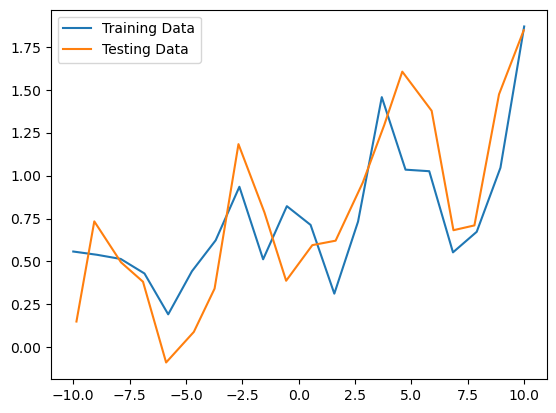

In [32]:
plt.plot(X, T, label='Training Data')
plt.plot(Xtest, Ttest, label='Testing Data')
plt.legend();

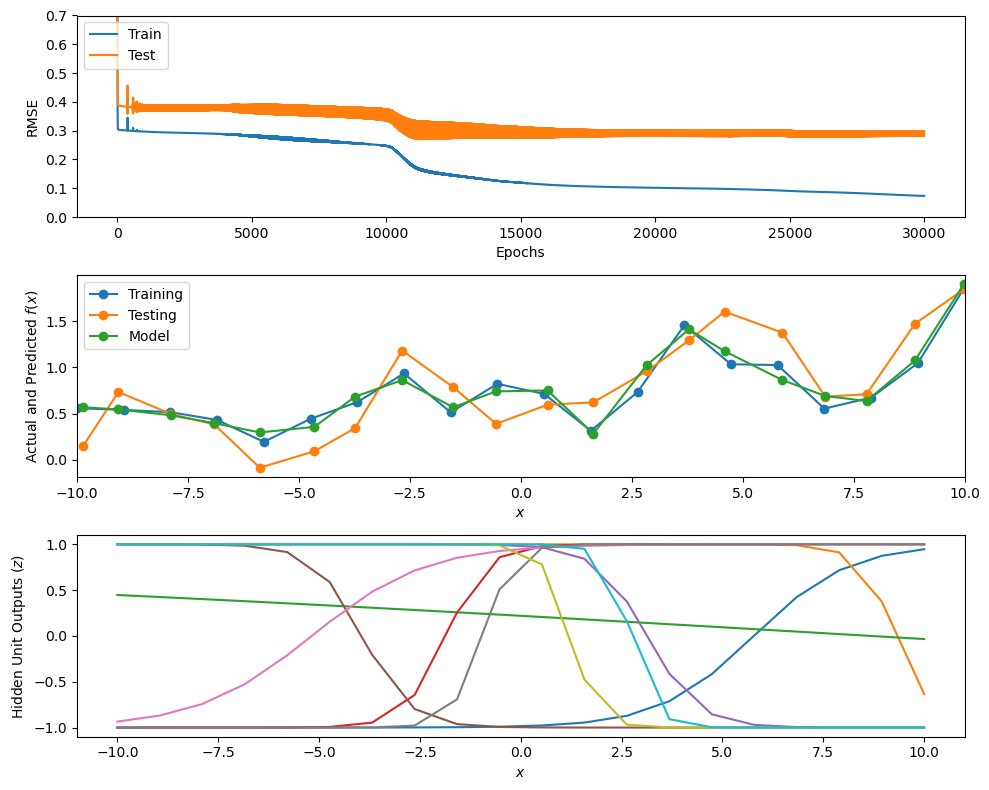

In [33]:
# Set parameters of neural network
nHiddens = 10

rhoh = 0.5
rhoo = 0.1

rh = rhoh / (nSamples * nOutputs)
ro = rhoo / (nSamples * nOutputs)

# Initialize weights to uniformly distributed values between small normally-distributed between -0.1 and 0.1
V = 0.1 * 2 * (np.random.uniform(size=(1 + 1, nHiddens)) - 0.5)
W = 0.1 * 2 * (np.random.uniform(size=(1 + nHiddens, nOutputs)) - 0.5)

# Add constant column of 1's
def addOnes(A):
    return np.insert(A, 0, 1, axis=1)

X1 = addOnes(X)
Xtest1 = addOnes(Xtest)

# Take nSteps steepest descent steps in gradient descent search in mean-squared-error function
nSteps = 30000

# collect training and testing errors for plotting
errorTrace = np.zeros((nSteps, 2))

fig = plt.figure(figsize=(10 ,8))

for step in range(nSteps):

    # Forward pass on training data
    Z = np.tanh(X1 @ V)
    #Z = 1 / (1 + np.exp(-(X1 @ V)))
    Z1 = addOnes(Z)
    Y = Z1 @ W

    # Error in output
    error = T - Y

    # Backward pass - the backpropagation and weight update steps
    V = V + rh * X1.T @ ( ( error @ W[1:, :].T) * (1 - Z**2))
    W = W + ro * Z1.T @ error

    # error traces for plotting
    errorTrace[step, 0] = np.sqrt(np.mean((error**2)))

    
    #Z = 1 / (1 + np.exp(-(Xtest1 @ V)))
    #Ytest = addOnes(Z) @ W 
    Ytest = addOnes(np.tanh(Xtest1 @ V)) @ W 
    errorTrace[step, 1] = np.sqrt(np.mean((Ytest - Ttest)**2))

    if step % 1000 == 0 or step == nSteps-1:
        plt.clf()
        
        # Plot the trace of the mean squared error on training and testing data
        plt.subplot(3, 1, 1)
        plt.plot(errorTrace[:step, :])
        plt.ylim(0, 0.7)
        plt.xlabel('Epochs')
        plt.ylabel('RMSE')
        plt.legend(('Train','Test'), loc='upper left')
        
        # Plot the training and testing data, and 
        # the output of our neural network model on the test data
        plt.subplot(3, 1, 2)
        plt.plot(X, T, 'o-', Xtest, Ttest, 'o-', Xtest, Ytest, 'o-')
        plt.xlim(-10, 10)
        plt.legend(('Training','Testing','Model'), loc='upper left')
        plt.xlabel('$x$')
        plt.ylabel('Actual and Predicted $f(x)$')
        
        # Plot the output of the hidden layer for each training sample
        plt.subplot(3, 1, 3)
        plt.plot(X, Z)
        plt.ylim(-1.1, 1.1)
        plt.xlabel('$x$')
        plt.ylabel('Hidden Unit Outputs ($z$)');

        plt.tight_layout() ###############
        
        ipd.clear_output(wait=True)
        ipd.display(fig)
ipd.clear_output(wait=True)


## Let's port this to PyTorch

### Imports and converting the data to tensors

In [34]:
import torch
import torch.nn as nn

# The dataset is tiny (20 samples), so the CPU is faster than a GPU here
device = torch.device('cpu')

# Convert the existing NumPy arrays (X, T, Xtest, Ttest) to tensors
Xt     = torch.from_numpy(X).float().to(device)
Tt     = torch.from_numpy(T).float().to(device)
Xtestt = torch.from_numpy(Xtest).float().to(device)
Ttestt = torch.from_numpy(Ttest).float().to(device)

nSamples, nInputs = Xt.shape
nOutputs = Tt.shape[1]

### Defining the model

- nn.Linear handles the bias internally

In [35]:
class Net(nn.Module):
    def __init__(self, n_inputs, n_hiddens, n_outputs):
        super().__init__()
        self.hidden = nn.Linear(n_inputs, n_hiddens)   # replaces V
        self.output = nn.Linear(n_hiddens, n_outputs)  # replaces W
        # Same init as NumPy: uniform in [-0.1, 0.1] for weights and biases
        for layer in (self.hidden, self.output):
            nn.init.uniform_(layer.weight, -0.1, 0.1)
            nn.init.uniform_(layer.bias, -0.1, 0.1)

    def forward(self, x):
        z = torch.tanh(self.hidden(x))
        y = self.output(z)
        return y, z          # return z too, so we can plot hidden units

nHiddens = 10

model = Net(nInputs, nHiddens, nOutputs).to(device)

### Loss and optimizer 

In [36]:
rhoh = 0.5
rhoo = 0.1

optimizer = torch.optim.SGD([
    {'params': model.hidden.parameters(), 'lr': rhoh},
    {'params': model.output.parameters(), 'lr': rhoo},
])

def loss_fn(Y, T):
    return 0.5 * torch.mean((T - Y) ** 2)

### Training loop with live plots

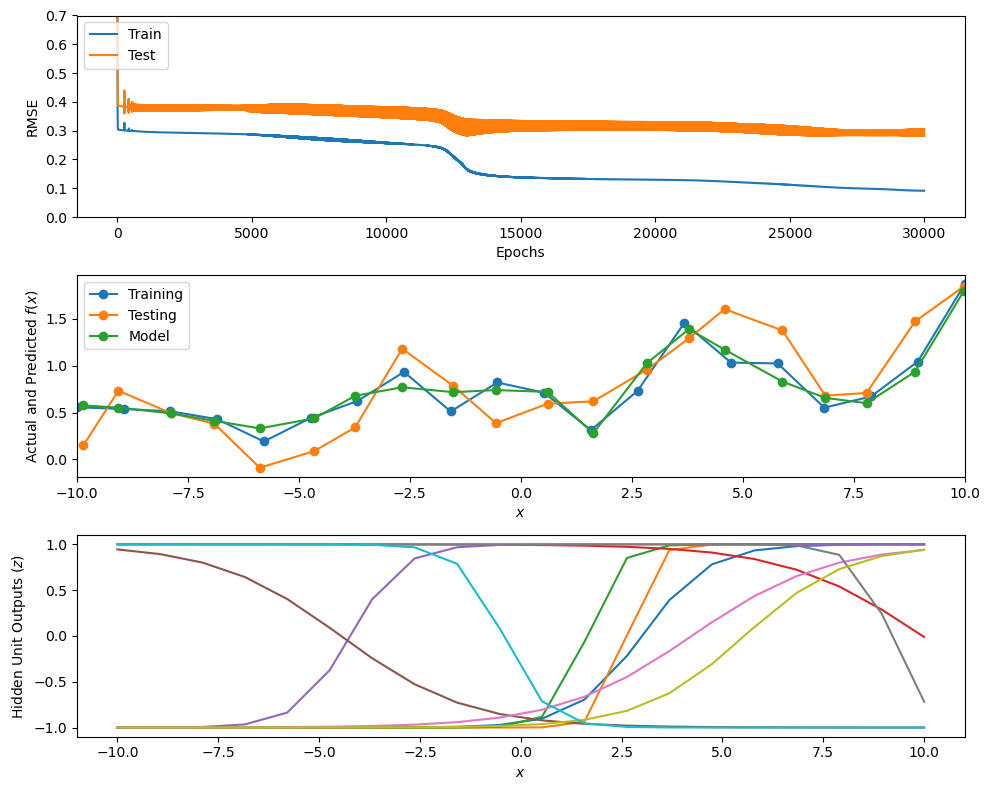

In [37]:
nSteps = 30000
errorTrace = np.zeros((nSteps, 2))

fig = plt.figure(figsize=(10, 8))

for step in range(nSteps):

    # Forward pass on training data
    Y, Z = model(Xt)
    loss = loss_fn(Y, Tt)

    # Backward pass and weight update (replaces the manual V and W updates)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Error traces (RMSE)
    with torch.no_grad():
        errorTrace[step, 0] = torch.sqrt(torch.mean((Tt - Y) ** 2)).item()
        Ytest, _ = model(Xtestt)
        errorTrace[step, 1] = torch.sqrt(torch.mean((Ytest - Ttestt) ** 2)).item()

    if step % 1000 == 0 or step == nSteps - 1:
        # Convert to NumPy for matplotlib
        Ytest_np = Ytest.cpu().numpy()
        Z_np = Z.detach().cpu().numpy()

        plt.clf()

        plt.subplot(3, 1, 1)
        plt.plot(errorTrace[:step, :])
        plt.ylim(0, 0.7)
        plt.xlabel('Epochs')
        plt.ylabel('RMSE')
        plt.legend(('Train', 'Test'), loc='upper left')

        plt.subplot(3, 1, 2)
        plt.plot(X, T, 'o-', Xtest, Ttest, 'o-', Xtest, Ytest_np, 'o-')
        plt.xlim(-10, 10)
        plt.legend(('Training', 'Testing', 'Model'), loc='upper left')
        plt.xlabel('$x$')
        plt.ylabel('Actual and Predicted $f(x)$')

        plt.subplot(3, 1, 3)
        plt.plot(X, Z_np)
        plt.ylim(-1.1, 1.1)
        plt.xlabel('$x$')
        plt.ylabel('Hidden Unit Outputs ($z$)')

        plt.tight_layout()
        ipd.clear_output(wait=True)
        ipd.display(fig)

ipd.clear_output(wait=True)